In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# -------------------------------
# 1. Configure project folders
# -------------------------------
from pathlib import Path

# Your project folder
BASE_DIR = Path(r"C:\Users\Tanvi\OneDrive\Desktop\Megaproject")

DATA_DIR = BASE_DIR / "datasets"
OUTPUT_DIR = BASE_DIR / "cleaned_data"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", BASE_DIR)
print("Dataset folder:", DATA_DIR)
print("Output folder:", OUTPUT_DIR)
print("Dataset folder exists:", DATA_DIR.exists())

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

file_path = DATA_DIR / "TY_ODD_AttendanceReport.xls"

if not file_path.exists():
    raise FileNotFoundError(f"File not found: {file_path}")

# -------------------------------
# 2. Read the source file
# -------------------------------
# Some .xls exports are actually HTML files.
with open(file_path, "rb") as f:
    signature = f.read(512).lstrip().lower()

if signature.startswith(b"<!doctype html") or \
   signature.startswith(b"<html") or \
   b"<table" in signature:
    tables = pd.read_html(file_path)
    if not tables:
        raise ValueError("No HTML tables found in the file.")
    df = tables[0]
else:
    df = pd.read_excel(file_path, engine="xlrd")

print("\nOriginal dataset shape:", df.shape)
print("\nOriginal column names:")
print(df.columns.tolist())
print("\nFirst five rows:")
print(df.head())

# -------------------------------
# 3. Remove completely empty rows
#    and columns
# -------------------------------
df = df.dropna(axis=0, how="all")
df = df.dropna(axis=1, how="all")

# -------------------------------
# 4. Standardize column names
# -------------------------------
def clean_column_name(name):
    name = str(name).strip().lower()
    name = name.replace("%", "percent")
    name = "".join(
        ch if ch.isalnum() else "_"
        for ch in name
    )

    while "__" in name:
        name = name.replace("__", "_")

    return name.strip("_")

# Preserve original column names for audit.
original_columns = df.columns.tolist()
cleaned_columns = [clean_column_name(c) for c in original_columns]

# Avoid accidentally creating duplicate column names.
seen = {}
unique_columns = []

for col in cleaned_columns:
    count = seen.get(col, 0)
    seen[col] = count + 1

    if count > 0:
        unique_columns.append(f"{col}_{count + 1}")
    else:
        unique_columns.append(col)

df.columns = unique_columns

print("\nStandardized columns:")
print(df.columns.tolist())

# -------------------------------
# 5. Inspect missing values
# -------------------------------
print("\nMissing values before further cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# -------------------------------
# 6. Inspect exact duplicate rows
# -------------------------------
print("\nExact duplicate rows:", df.duplicated().sum())

# Do not automatically remove duplicates.
# Review them before deciding whether they
# represent genuinely repeated records.

# -------------------------------
# 7. Inspect percentage columns
# -------------------------------
percentage_columns = [
    col for col in df.columns
    if "attendance" in col and "percent" in col
]

for col in percentage_columns:
    # Convert only columns that contain numeric
    # attendance percentages.
    df[col] = pd.to_numeric(df[col], errors="coerce")

    invalid = df[
        df[col].notna() &
        ~df[col].between(0, 100)
    ]

    print(f"\nInvalid percentages in {col}:")
    print(invalid[[col]].head(10))
    print("Invalid count:", len(invalid))

# -------------------------------
# 8. Save a cleaned copy
# -------------------------------
output_path = OUTPUT_DIR / "TY_ODD_AttendanceReport_cleaned.csv"

df.to_csv(output_path, index=False)

print("\nFinal dataset shape:", df.shape)
print("Cleaned file saved to:", output_path)
print("\nCleaning script completed.")


Project folder: C:\Users\Tanvi\OneDrive\Desktop\Megaproject
Dataset folder: C:\Users\Tanvi\OneDrive\Desktop\Megaproject\datasets
Output folder: C:\Users\Tanvi\OneDrive\Desktop\Megaproject\cleaned_data
Dataset folder exists: True

Original dataset shape: (202, 27)

Original column names:
[('Academic Year: 2025-26', 'Department: Computer Science and Engineering', 'Start Date - 01 July, 2025 | End Date - 31 May, 2026', 'SEM-I-Final Year-C', 'Sr. No.', 'Faculty Incharge', 'Faculty Incharge'), ('Academic Year: 2025-26', 'Department: Computer Science and Engineering', 'Start Date - 01 July, 2025 | End Date - 31 May, 2026', 'SEM-I-Final Year-C', 'Roll No.', 'Faculty Incharge', 'Faculty Incharge'), ('Academic Year: 2025-26', 'Department: Computer Science and Engineering', 'Start Date - 01 July, 2025 | End Date - 31 May, 2026', 'SEM-I-Final Year-C', 'Student Name', 'Faculty Incharge', 'Faculty Incharge'), ('Academic Year: 2025-26', 'Department: Computer Science and Engineering', 'Start Date - 0

In [8]:
from pathlib import Path
import pandas as pd

# Project folders
BASE_DIR = Path(
    r"C:\Users\Tanvi\OneDrive\Desktop\Megaproject"
)
DATA_DIR = BASE_DIR / "cleaned_data"

# Updated filenames
SY_FILE = DATA_DIR / "SY_C_Sem2_2024_25_Attendance.csv"
TY_FILE = DATA_DIR / "TY_C_Sem2_2025_26_Attendance.csv"

# Verify files exist
for file in [SY_FILE, TY_FILE]:
    print(f"{file.name}: {'Found' if file.exists() else 'NOT FOUND'}")

if SY_FILE.exists() and TY_FILE.exists():
    sy = pd.read_csv(SY_FILE)
    ty = pd.read_csv(TY_FILE)

    print("\nSY dataset shape:", sy.shape)
    print("TY dataset shape:", ty.shape)

    print("\nSY columns:")
    print(sy.columns.tolist())

    print("\nTY columns:")
    print(ty.columns.tolist())


SY_C_Sem2_2024_25_Attendance.csv: Found
TY_C_Sem2_2025_26_Attendance.csv: Found

SY dataset shape: (83, 41)
TY dataset shape: (170, 40)

SY columns:
['academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_sr_no_faculty_incharge_faculty_incharge', 'academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_roll_no_faculty_incharge_faculty_incharge', 'academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_student_name_faculty_incharge_faculty_incharge', 'academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_group_faculty_incharge_faculty_incharge', 'academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_mentor_name_faculty_incharge_faculty_incharge', 'acad

In [9]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"C:\Users\Tanvi\OneDrive\Desktop\Megaproject")
DATA_DIR = BASE_DIR / "cleaned_data"

sy = pd.read_csv(DATA_DIR / "SY_C_Sem2_2024_25_Attendance.csv")
ty = pd.read_csv(DATA_DIR / "TY_C_Sem2_2025_26_Attendance.csv")

def find_column(df, keyword):
    matches = [c for c in df.columns if keyword in c.lower()]
    if len(matches) != 1:
        print(f"Columns matching '{keyword}':", matches)
        raise ValueError(f"Expected one matching column for '{keyword}'.")
    return matches[0]

# Identify the important columns
sy_roll = find_column(sy, "_roll_no_")
sy_name = find_column(sy, "_student_name_")
sy_att = find_column(sy, "total_attendance_percent")

ty_roll = find_column(ty, "_roll_no_")
ty_name = find_column(ty, "_student_name_")
ty_att = find_column(ty, "total_attendance_percent")

# Create a simple view of each dataset
sy_check = pd.DataFrame({
    "SY_roll": sy[sy_roll],
    "SY_name": sy[sy_name],
    "SY_attendance": pd.to_numeric(sy[sy_att], errors="coerce")
})

ty_check = pd.DataFrame({
    "TY_roll": ty[ty_roll],
    "TY_name": ty[ty_name],
    "TY_attendance": pd.to_numeric(ty[ty_att], errors="coerce")
})

# Normalize names for comparison
for df, col in [(sy_check, "SY_name"), (ty_check, "TY_name")]:
    df["normalized_name"] = (
        df[col].fillna("").astype(str).str.strip().str.upper()
        .str.replace(r"\s+", " ", regex=True)
    )

sy_names = set(sy_check["normalized_name"]) - {""}
ty_names = set(ty_check["normalized_name"]) - {""}
common_names = sy_names & ty_names

print("SY rows:", len(sy_check))
print("TY rows:", len(ty_check))
print("Unique SY names:", len(sy_names))
print("Unique TY names:", len(ty_names))
print("Names appearing in both datasets:", len(common_names))

print("\nFirst 10 SY records:")
print(sy_check.head(10).to_string(index=False))

print("\nFirst 10 TY records:")
print(ty_check.head(10).to_string(index=False))

print("\nDuplicate names in SY:")
print(sy_check[sy_check["normalized_name"].duplicated(keep=False)]
      [["SY_roll", "SY_name"]].to_string(index=False))

print("\nDuplicate names in TY:")
print(ty_check[ty_check["normalized_name"].duplicated(keep=False)]
      [["TY_roll", "TY_name"]].to_string(index=False))


SY rows: 83
TY rows: 170
Unique SY names: 82
Unique TY names: 169
Names appearing in both datasets: 82

First 10 SY records:
SY_roll            SY_name  SY_attendance    normalized_name
  SYC01      TEJAS ALAWANI          66.52      TEJAS ALAWANI
  SYC02     NIRJALA PUJARI          86.88     NIRJALA PUJARI
  SYC03        SAHIL CHILE          78.73        SAHIL CHILE
  SYC04      SANIKA RANAGE          82.35      SANIKA RANAGE
  SYC05  SAMIKSHA PAVASKAR          73.76  SAMIKSHA PAVASKAR
  SYC06   MAITHILI DHOPATE          82.35   MAITHILI DHOPATE
  SYC07       AMRUTA POWAR          88.24       AMRUTA POWAR
  SYC08         DHIREN ADE          55.66         DHIREN ADE
  SYC09   PRANAV NIMBALKAR          76.47   PRANAV NIMBALKAR
  SYC10 SATYAJEET GONUGADE          81.45 SATYAJEET GONUGADE

First 10 TY records:
TY_roll            TY_name  TY_attendance    normalized_name
  TYC01      TEJAS ALAWANI          77.24      TEJAS ALAWANI
  TYC02     NIRJALA PUJARI          88.99     NIRJALA PUJARI

In [10]:

# Extract the numeric suffix from each roll number.
# Example: SYC19 -> 19, TYC19 -> 19

sy_check["roll_suffix"] = (
    sy_check["SY_roll"].astype(str).str.extract(r"(\d+)$")[0]
)
ty_check["roll_suffix"] = (
    ty_check["TY_roll"].astype(str).str.extract(r"(\d+)$")[0]
)

# Match on both name and roll suffix
matched = sy_check.merge(
    ty_check,
    on=["normalized_name", "roll_suffix"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("Total SY records:", len(sy_check))
print("Successfully matched:", (matched["_merge"] == "both").sum())
print("Unmatched SY records:", (matched["_merge"] == "left_only").sum())
print("Duplicate matched pairs:", matched.duplicated(
    subset=["SY_roll", "TY_roll"]
).sum())

print("\nMatched student pairs:")
print(
    matched[[
        "SY_roll", "SY_name", "TY_roll",
        "SY_attendance", "TY_attendance", "_merge"
    ]].to_string(index=False)
)

print("\nUnmatched records, if any:")
print(
    matched.loc[matched["_merge"] != "both",
                ["SY_roll", "SY_name", "roll_suffix", "_merge"]]
    .to_string(index=False)
)


Total SY records: 83
Successfully matched: 83
Unmatched SY records: 0
Duplicate matched pairs: 0

Matched student pairs:
SY_roll                 SY_name TY_roll  SY_attendance  TY_attendance _merge
  SYC01           TEJAS ALAWANI   TYC01          66.52          77.24   both
  SYC02          NIRJALA PUJARI   TYC02          86.88          88.99   both
  SYC03             SAHIL CHILE   TYC03          78.73          86.90   both
  SYC04           SANIKA RANAGE   TYC04          82.35          83.49   both
  SYC05       SAMIKSHA PAVASKAR   TYC05          73.76          82.57   both
  SYC06        MAITHILI DHOPATE   TYC06          82.35          84.40   both
  SYC07            AMRUTA POWAR   TYC07          88.24          85.32   both
  SYC08              DHIREN ADE   TYC08          55.66          73.39   both
  SYC09        PRANAV NIMBALKAR   TYC09          76.47          77.93   both
  SYC10      SATYAJEET GONUGADE   TYC10          81.45          77.24   both
  SYC11         SUNIDHI GHODAKE 

In [11]:

# Summarize historical attendance features without printing long column names

subject_percent_cols = [
    c for c in sy.columns
    if "_percent" in c.lower()
    and "_average_percent_" not in c.lower()
    and "_total_attendance_percent_" not in c.lower()
]

present_cols = [c for c in sy.columns if "_present_sessions" in c.lower()]
total_cols = [c for c in sy.columns if "_total_sessions" in c.lower()]

feature_cols = subject_percent_cols + present_cols + total_cols

print("Subject percentage columns:", len(subject_percent_cols))
print("Present-session columns:", len(present_cols))
print("Total-session columns:", len(total_cols))
print("Total candidate features:", len(feature_cols))

print("\nMissing values across candidate features:",
      int(sy[feature_cols].isna().sum().sum()))

print("Completely empty columns:",
      int(sy[feature_cols].isna().all().sum()))

print("\nOverall SY attendance missing:",
      int(sy[sy_att].isna().sum()))

print("Overall TY attendance missing:",
      int(ty[ty_att].isna().sum()))


Subject percentage columns: 11
Present-session columns: 11
Total-session columns: 11
Total candidate features: 33

Missing values across candidate features: 0
Completely empty columns: 0

Overall SY attendance missing: 0
Overall TY attendance missing: 87


In [12]:

# Check TY attendance only for the 83 matched students

matched_ty = matched[matched["_merge"] == "both"].copy()

print("Matched students:", len(matched_ty))
print("Matched students with missing TY attendance:",
      matched_ty["TY_attendance"].isna().sum())
print("Matched students with valid TY attendance:",
      matched_ty["TY_attendance"].notna().sum())

print("\nMissing TY attendance examples:")
print(
    matched_ty.loc[
        matched_ty["TY_attendance"].isna(),
        ["SY_roll", "SY_name", "TY_roll"]
    ].head(10).to_string(index=False)
)


Matched students: 83
Matched students with missing TY attendance: 0
Matched students with valid TY attendance: 83

Missing TY attendance examples:
Empty DataFrame
Columns: [SY_roll, SY_name, TY_roll]
Index: []


In [13]:

# Create the modelling dataset for the 83 matched students

# Match SY feature rows to TY targets using the verified student pairs
model_data = matched.copy()

# Add the 33 historical subject/session features from SY
sy_features = sy[feature_cols].copy()
sy_features = sy_features.reset_index(drop=True)

# Keep rows in the same order as the verified SY-to-TY matches
model_data = model_data.reset_index(drop=True)

X = pd.concat(
    [
        model_data[["SY_attendance"]].reset_index(drop=True),
        sy_features
    ],
    axis=1
)

# Target: overall attendance in the later semester
y = model_data["TY_attendance"].reset_index(drop=True)

# Convert features to numeric values
X = X.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")

# Remove duplicate feature columns, if any
X = X.loc[:, ~X.columns.duplicated()]

# Check the final dataset
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Missing feature values:", int(X.isna().sum().sum()))
print("Missing target values:", int(y.isna().sum()))
print("Duplicate feature names:", int(X.columns.duplicated().sum()))

print("\nTarget attendance summary:")
print(y.describe().round(2).to_string())


Feature matrix shape: (83, 34)
Target shape: (83,)
Missing feature values: 0
Missing target values: 0
Duplicate feature names: 0

Target attendance summary:
count    83.00
mean     78.29
std       8.24
min      59.63
25%      73.24
50%      78.90
75%      83.45
max      98.17


In [14]:

# Check whether any features are constant or redundant

constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

duplicate_cols = X.columns[X.T.duplicated()].tolist()

print("Total features:", X.shape[1])
print("Constant features:", len(constant_cols))
print("Duplicate-value features:", len(duplicate_cols))

if constant_cols:
    print("\nConstant feature names:")
    print(constant_cols)

if duplicate_cols:
    print("\nDuplicate feature names:")
    print(duplicate_cols)

print("\nFeature examples:")
print(X.iloc[:, :8].head(3).round(2).to_string(index=False))


Total features: 34
Constant features: 17
Duplicate-value features: 9

Constant feature names:
['academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_optimization_methods_for_analytics_mdm_ii_t_nikhilesh_soundattikar_percent', 'academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_introduction_to_security_of_cyber_physical_systems_mdm_ii_t_anesh_kshirsagar_percent', 'academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_bioimaging_mdm_ii_t_raviraj_havaldar_percent', 'academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_optimization_methods_for_analytics_mdm_ii_t_nikhilesh_soundattikar_present_sessions', 'academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_

In [15]:

# Remove constant and duplicate-value features

X_clean = X.copy()

# 1. Remove constant columns
constant_cols = [
    col for col in X_clean.columns
    if X_clean[col].nunique(dropna=False) <= 1
]
X_clean = X_clean.drop(columns=constant_cols)

# 2. Remove duplicate-value columns, keeping the first copy
duplicate_cols = X_clean.columns[X_clean.T.duplicated()].tolist()
X_clean = X_clean.drop(columns=duplicate_cols)

print("Original feature count:", X.shape[1])
print("Constant columns removed:", len(constant_cols))
print("Duplicate-value columns removed:", len(duplicate_cols))
print("Remaining feature count:", X_clean.shape[1])
print("Missing values:", int(X_clean.isna().sum().sum()))

print("\nRemaining feature groups:")
print("Overall SY attendance included:", "SY_attendance" in X_clean.columns)
print("Subject percentage features:",
      sum("_percent" in c.lower() for c in X_clean.columns))
print("Present-session features:",
      sum("_present_sessions" in c.lower() for c in X_clean.columns))
print("Total-session features:",
      sum("_total_sessions" in c.lower() for c in X_clean.columns))


Original feature count: 34
Constant columns removed: 17
Duplicate-value columns removed: 1
Remaining feature count: 16
Missing values: 0

Remaining feature groups:
Overall SY attendance included: True
Subject percentage features: 7
Present-session features: 8
Total-session features: 0


In [16]:

# Display remaining features with shortened names

for i, col in enumerate(X_clean.columns, start=1):
    if col == "SY_attendance":
        short_name = "Previous overall attendance"
    elif "_present_sessions" in col.lower():
        short_name = col.split("_sy_c_")[-1].split("_present_sessions")[0] + " (present)"
    elif "_percent" in col.lower():
        short_name = col.split("_sy_c_")[-1].split("_percent")[0] + " (%)"
    else:
        short_name = col

    print(f"{i}. {short_name}")


1. Previous overall attendance
2. operating_systems_t_deepali_jadhav (%)
3. computational_mathematics_t_swapnali_patil (%)
4. automata_theory_t_anuradha_solanki (%)
5. introduction_to_artificial_intelligence_t_reecha_suryavanshi (%)
6. web_technologies_t_ajay_kapase (%)
7. environmental_studies_t_minal_gune (%)
8. advanced_programming_laboratory_theory_t_ajay_kapase (%)
9. operating_systems_t_deepali_jadhav (present)
10. computational_mathematics_t_swapnali_patil (present)
11. automata_theory_t_anuradha_solanki (present)
12. introduction_to_artificial_intelligence_t_reecha_suryavanshi (present)
13. web_technologies_t_ajay_kapase (present)
14. environmental_studies_t_minal_gune (present)
15. advanced_programming_laboratory_theory_t_ajay_kapase (present)
16. total_unnamed_36_level_5 (present)


In [17]:

# Print only the unclear aggregate column's values and summary

aggregate_col = [
    c for c in X_clean.columns
    if "total_unnamed" in c.lower()
]

for col in aggregate_col:
    print("Column:", col)
    print("Unique values:", X_clean[col].nunique())
    print("Minimum:", X_clean[col].min())
    print("Maximum:", X_clean[col].max())
    print("First 10 values:", X_clean[col].head(10).tolist())


Column: academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_total_unnamed_36_level_5_present_sessions
Unique values: 50
Minimum: 123
Maximum: 208
First 10 values: [147, 192, 174, 182, 163, 182, 195, 123, 169, 180]


In [20]:

from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import pandas as pd
import numpy as np

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=5,
        random_state=42,
        objective="reg:squarederror"
    )
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_clean,
        y,
        cv=kf,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        }
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean(),
        "Mean R2": scores["test_r2"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).round(3)
print(cv_results_df.to_string(index=False))


            Model  Mean MAE  Mean RMSE  Mean R2
Linear Regression     3.889      4.850    0.567
    Random Forest     3.433      4.473    0.641
          XGBoost     3.717      4.746    0.591


In [24]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

# --------------------------------------------------
# 1. INPUTS AND TARGET
# --------------------------------------------------
# X_clean = SY attendance features for matched students
# y       = actual TY overall attendance for those students

X = X_clean.copy()
target = pd.Series(y, index=X.index, name="TY_attendance")

# --------------------------------------------------
# 2. CALCULATE MODEL WEIGHTS FROM CV MAE
# --------------------------------------------------
rf_cv_mae = 3.433
xgb_cv_mae = 3.717

inverse_errors = np.array([
    1 / rf_cv_mae,
    1 / xgb_cv_mae
])

weights = inverse_errors / inverse_errors.sum()

rf_weight = weights[0]
xgb_weight = weights[1]

print(f"Random Forest weight: {rf_weight:.3f}")
print(f"XGBoost weight:       {xgb_weight:.3f}")

# --------------------------------------------------
# 3. SPLIT THE MATCHED DATA
# --------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, target,
    test_size=0.2,
    random_state=42
)

# --------------------------------------------------
# 4. DEFINE THE MODELS
# --------------------------------------------------
rf_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42
)

xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=5,
    random_state=42,
    objective="reg:squarederror"
)

# --------------------------------------------------
# 5. TRAIN BOTH MODELS
# --------------------------------------------------
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

# --------------------------------------------------
# 6. COMBINE PREDICTIONS
# --------------------------------------------------
rf_predictions = rf_model.predict(X_test)
xgb_predictions = xgb_model.predict(X_test)

hybrid_predictions = (
    rf_weight * rf_predictions
    + xgb_weight * xgb_predictions
)

# Attendance is expressed as a percentage.
# Clip predictions to the valid 0–100 range.
hybrid_predictions = np.clip(hybrid_predictions, 0, 100)

# --------------------------------------------------
# 7. DISPLAY ACTUAL VS PREDICTED ATTENDANCE
# --------------------------------------------------
comparison = pd.DataFrame({
    "Actual_TY_Attendance": y_test.to_numpy(),
    "RF_Prediction": rf_predictions,
    "XGBoost_Prediction": xgb_predictions,
    "Hybrid_Prediction": hybrid_predictions
}, index=y_test.index)

print("\nActual vs Predicted Attendance:")
print(comparison.round(2).to_string())

# --------------------------------------------------
# 8. EVALUATE THE HYBRID
# --------------------------------------------------
print("\nHybrid Model Performance")
print("MAE:", round(
    mean_absolute_error(y_test, hybrid_predictions), 3
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test, hybrid_predictions)), 3
))
print("R2:", round(
    r2_score(y_test, hybrid_predictions), 3
))


Random Forest weight: 0.520
XGBoost weight:       0.480

Actual vs Predicted Attendance:
    Actual_TY_Attendance  RF_Prediction  XGBoost_Prediction  Hybrid_Prediction
30                 78.90          78.87           79.080002              78.97
0                  77.24          66.13           67.510002              66.79
22                 82.07          82.39           82.199997              82.30
31                 77.98          72.61           71.669998              72.16
18                 73.10          67.71           69.089996              68.37
28                 65.14          68.08           67.730003              67.91
10                 85.32          75.58           78.779999              77.12
53                 80.00          89.68           88.290001              89.02
4                  82.57          78.12           77.320000              77.74
12                 63.45          74.64           77.300003              75.92
49                 81.38          80.49   

In [25]:

import pandas as pd
import numpy as np

# Compare actual attendance with hybrid predictions
error_analysis = pd.DataFrame({
    "Actual_Attendance": y_test.values,
    "RF_Prediction": rf_predictions,
    "XGBoost_Prediction": xgb_predictions,
    "Hybrid_Prediction": hybrid_predictions
}, index=y_test.index)

error_analysis["Error"] = (
    error_analysis["Actual_Attendance"]
    - error_analysis["Hybrid_Prediction"]
)

error_analysis["Absolute_Error"] = error_analysis["Error"].abs()

# Display students with the largest prediction errors
error_analysis = error_analysis.sort_values(
    by="Absolute_Error", ascending=False
)

print("Students with the largest prediction errors:")
display(error_analysis.head(10).round(2))

print("\nMean Absolute Error:")
print(round(error_analysis["Absolute_Error"].mean(), 3))


Students with the largest prediction errors:


,Actual_Attendance,RF_Prediction,XGBoost_Prediction,Hybrid_Prediction,Error,Absolute_Error
12,63.45,74.64,77.300003,75.92,-12.47,12.47
0,77.24,66.13,67.510002,66.79,10.45,10.45
53,80.00,89.68,88.290001,89.02,-9.02,9.02
70,59.63,67.96,67.690002,67.83,-8.20,8.20
10,85.32,75.58,78.779999,77.12,8.20,8.20
31,77.98,72.61,71.669998,72.16,5.82,5.82
4,82.57,78.12,77.320000,77.74,4.83,4.83
18,73.10,67.71,69.089996,68.37,4.73,4.73
75,92.66,88.94,87.379997,88.19,4.47,4.47
69,93.58,91.41,88.470001,90.00,3.58,3.58



Mean Absolute Error:
4.749


In [30]:
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42
)

model.fit(X_clean, y)

importance = pd.DataFrame({
    "Feature": X_clean.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance.head(10).round(4))

,Feature,Importance
15,academic_year_2024_25_department_computer_scie...,0.1850
8,academic_year_2024_25_department_computer_scie...,0.1840
1,academic_year_2024_25_department_computer_scie...,0.1667
0,SY_attendance,0.1645
13,academic_year_2024_25_department_computer_scie...,0.0669
6,academic_year_2024_25_department_computer_scie...,0.0417
9,academic_year_2024_25_department_computer_scie...,0.0328
3,academic_year_2024_25_department_computer_scie...,0.0323
10,academic_year_2024_25_department_computer_scie...,0.0299
2,academic_year_2024_25_department_computer_scie...,0.0267


In [32]:

from sklearn.model_selection import KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

# 1. Set up 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Select the top 4 features
top_features = [
    "SY_attendance",
    [c for c in X_clean.columns
     if "total_unnamed_36_level_5_present_sessions" in c][0],
    [c for c in X_clean.columns
     if "operating_systems_t_deepali_jadhav_present_sessions" in c][0],
    [c for c in X_clean.columns
     if "operating_systems_t_deepali_jadhav_percent" in c][0]
]

X_top4 = X_clean[top_features]

# 3. Define the evaluation function
def evaluate(features):
    model = RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42
    )

    scores = cross_validate(
        model,
        features,
        y,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        }
    )

    return {
        "MAE": -scores["test_mae"].mean(),
        "RMSE": -scores["test_rmse"].mean(),
        "R2": scores["test_r2"].mean()
    }

# 4. Compare all three feature sets
comparison = pd.DataFrame({
    "Previous attendance only": evaluate(
        X_clean[["SY_attendance"]]
    ),
    "Top 4 features": evaluate(X_top4),
    "All 16 features": evaluate(X_clean)
}).T

# 5. Display results
print("Top 4 features used:")
for feature in top_features:
    print("-", feature)

print("\nFeature comparison results:")
display(comparison.round(3))


Top 4 features used:
- SY_attendance
- academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_total_unnamed_36_level_5_present_sessions
- academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_operating_systems_t_deepali_jadhav_present_sessions
- academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_operating_systems_t_deepali_jadhav_percent

Feature comparison results:


,MAE,RMSE,R2
Previous attendance only,3.852,4.852,0.580
Top 4 features,3.665,4.585,0.624
All 16 features,3.433,4.473,0.641


In [34]:

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

X = X_clean.copy()
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rf = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42
)

xgb = XGBRegressor(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42
)

# Generate out-of-fold predictions
rf_pred = cross_val_predict(rf, X, y, cv=cv)
xgb_pred = cross_val_predict(xgb, X, y, cv=cv)

# Combine predictions using equal weights
hybrid_pred = 0.5 * rf_pred + 0.5 * xgb_pred

# Evaluate all predictions on the same out-of-fold students
def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

results = pd.DataFrame({
    "Random Forest": calculate_metrics(y, rf_pred),
    "XGBoost": calculate_metrics(y, xgb_pred),
    "Hybrid (50:50)": calculate_metrics(y, hybrid_pred)
}).T

display(results.round(3))


,MAE,RMSE,R2
Random Forest,3.436,4.566,0.689
XGBoost,3.714,4.843,0.650
Hybrid (50:50),3.535,4.639,0.679


In [35]:

# Analyze out-of-fold Random Forest prediction errors

error_analysis = pd.DataFrame({
    "Actual_Attendance": np.asarray(y).ravel(),
    "Predicted_Attendance": rf_pred
})

error_analysis["Error"] = (
    error_analysis["Predicted_Attendance"]
    - error_analysis["Actual_Attendance"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Error"].abs()
)

# Show students with the largest errors
error_analysis = error_analysis.sort_values(
    "Absolute_Error",
    ascending=False
)

display(error_analysis.head(10).round(2))

print("\nOverall error summary:")
print("MAE:", round(error_analysis["Absolute_Error"].mean(), 3))
print("Maximum absolute error:",
      round(error_analysis["Absolute_Error"].max(), 3))


,Actual_Attendance,Predicted_Attendance,Error,Absolute_Error
12,63.45,74.76,11.31,11.31
0,77.24,66.66,-10.58,10.58
74,98.17,88.05,-10.12,10.12
53,80.00,89.95,9.95,9.95
10,85.32,75.90,-9.42,9.42
7,73.39,64.10,-9.29,9.29
71,76.15,84.82,8.67,8.67
17,78.62,86.87,8.25,8.25
70,59.63,67.54,7.91,7.91
2,86.90,79.10,-7.80,7.80



Overall error summary:
MAE: 3.436
Maximum absolute error: 11.306


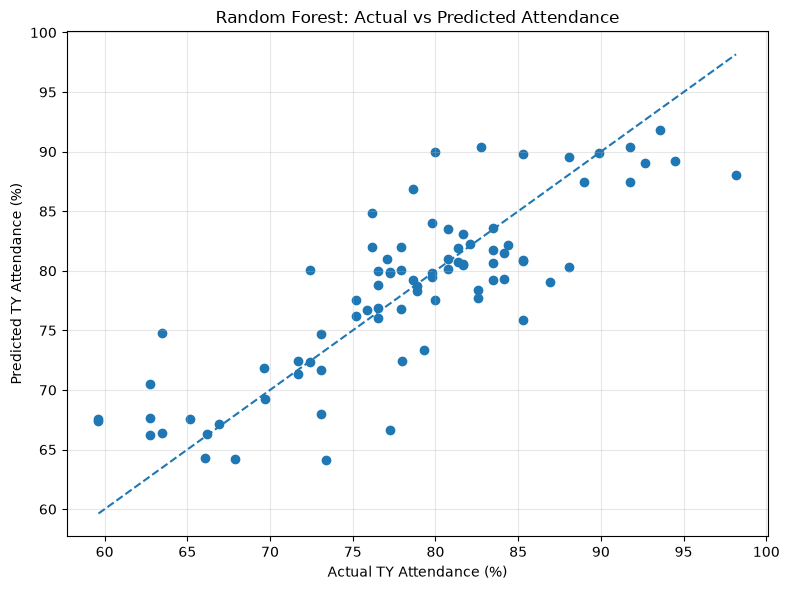

In [36]:

import matplotlib.pyplot as plt
import numpy as np

actual = np.asarray(y).ravel()
predicted = np.asarray(rf_pred).ravel()

plt.figure(figsize=(8, 6))

plt.scatter(actual, predicted)

# Perfect prediction reference line
min_value = min(actual.min(), predicted.min())
max_value = max(actual.max(), predicted.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual TY Attendance (%)")
plt.ylabel("Predicted TY Attendance (%)")
plt.title("Random Forest: Actual vs Predicted Attendance")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [39]:

import numpy as np
import pandas as pd

from scipy.stats import rankdata, norm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare the real dataset
X = X_clean.reset_index(drop=True).copy()
target = pd.Series(np.asarray(y).ravel(), name="TY_attendance")

data = pd.concat([X, target], axis=1)

# Split REAL students before generating synthetic data
train_data, test_data = train_test_split(
    data,
    test_size=0.20,
    random_state=42
)

train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print("Real training records:", len(train_data))
print("Real test records:", len(test_data))


# 2. Gaussian copula synthetic-data generator
def generate_synthetic_data(real_data, n_samples, random_state=42):
    rng = np.random.default_rng(random_state)

    values = real_data.to_numpy(dtype=float)
    n_rows, n_cols = values.shape

    # Convert each column's ranks into normal scores
    z = np.zeros_like(values, dtype=float)

    for j in range(n_cols):
        ranks = rankdata(values[:, j], method="average")
        probabilities = (ranks - 0.5) / n_rows
        z[:, j] = norm.ppf(probabilities)

    # Estimate relationships between columns
    correlation = np.corrcoef(z, rowvar=False)
    correlation = np.nan_to_num(
        correlation, nan=0.0, posinf=0.0, neginf=0.0
    )

    # Make the correlation matrix numerically stable
    eigenvalues, eigenvectors = np.linalg.eigh(correlation)
    eigenvalues = np.maximum(eigenvalues, 1e-6)

    correlation = (
        eigenvectors @ np.diag(eigenvalues) @ eigenvectors.T
    )

    scale = np.sqrt(np.diag(correlation))
    correlation = correlation / np.outer(scale, scale)

    # Sample correlated artificial normal values
    synthetic_z = rng.multivariate_normal(
        mean=np.zeros(n_cols),
        cov=correlation,
        size=n_samples
    )

    # Convert normal scores to uniform probabilities
    probabilities = norm.cdf(synthetic_z)

    # Map each column back to its observed value distribution
    synthetic = np.zeros_like(probabilities)

    for j in range(n_cols):
        sorted_values = np.sort(values[:, j])

        synthetic[:, j] = np.quantile(
            sorted_values,
            probabilities[:, j],
            method="linear"
        )

    return pd.DataFrame(
        synthetic,
        columns=real_data.columns
    )


# 3. Generate synthetic records from TRAINING data only
synthetic_data = generate_synthetic_data(
    train_data,
    n_samples=len(train_data),
    random_state=42
)

print("\nSynthetic records generated:", len(synthetic_data))
display(synthetic_data.head().round(2))


Real training records: 66
Real test records: 17

Synthetic records generated: 66


,SY_attendance,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_operating_systems_t_deepali_jadhav_percent,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_computational_mathematics_t_swapnali_patil_percent,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_automata_theory_t_anuradha_solanki_percent,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_introduction_to_artificial_intelligence_t_reecha_suryavanshi_percent,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_web_technologies_t_ajay_kapase_percent,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_environmental_studies_t_minal_gune_percent,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_advanced_programming_laboratory_theory_t_ajay_kapase_percent,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_operating_systems_t_deepali_jadhav_present_sessions,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_computational_mathematics_t_swapnali_patil_present_sessions,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_automata_theory_t_anuradha_solanki_present_sessions,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_introduction_to_artificial_intelligence_t_reecha_suryavanshi_present_sessions,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_web_technologies_t_ajay_kapase_present_sessions,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_environmental_studies_t_minal_gune_present_sessions,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_advanced_programming_laboratory_theory_t_ajay_kapase_present_sessions,academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_total_unnamed_36_level_5_present_sessions,TY_attendance
0,77.38,67.50,76.19,72.22,68.77,87.10,76.83,95.24,27.0,32.00,26.00,17.16,27.0,19.98,20.00,171.00,76.55
1,83.26,85.00,81.35,77.78,86.95,90.32,84.62,85.71,34.0,34.19,28.00,21.71,28.0,22.00,18.00,184.00,83.99
2,72.73,75.00,74.67,72.22,72.89,83.87,73.43,73.70,30.0,31.38,26.00,18.21,26.0,19.06,15.48,160.72,79.47
3,73.57,73.24,66.67,66.67,58.81,90.32,71.60,95.24,29.3,28.00,24.00,14.69,28.0,18.61,20.00,162.56,76.55
4,69.09,65.00,66.67,64.17,64.00,90.32,65.38,76.19,26.0,28.00,23.14,16.00,28.0,17.00,16.00,152.67,75.88


In [40]:

# Separate features and target
X_train = train_data[X.columns]
y_train = train_data["TY_attendance"]

X_test = test_data[X.columns]
y_test = test_data["TY_attendance"]

X_synthetic = synthetic_data[X.columns]
y_synthetic = synthetic_data["TY_attendance"]


def evaluate_rf(X_fit, y_fit, X_eval, y_eval):
    model = RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42
    )

    model.fit(X_fit, y_fit)
    predictions = model.predict(X_eval)

    return {
        "MAE": mean_absolute_error(y_eval, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_eval, predictions)),
        "R2": r2_score(y_eval, predictions)
    }


# Baseline: real training records only
real_results = evaluate_rf(
    X_train, y_train, X_test, y_test
)

# Experiment: real + synthetic training records
X_augmented = pd.concat(
    [X_train, X_synthetic],
    ignore_index=True
)

y_augmented = pd.concat(
    [y_train, y_synthetic],
    ignore_index=True
)

synthetic_results = evaluate_rf(
    X_augmented, y_augmented, X_test, y_test
)

comparison = pd.DataFrame({
    "Real data only": real_results,
    "Real + synthetic data": synthetic_results
}).T

display(comparison.round(3))


,MAE,RMSE,R2
Real data only,4.680,6.060,0.533
Real + synthetic data,4.637,6.068,0.532


In [41]:

# Compare correlations with future attendance
# Real training data vs synthetic data

real_correlations = train_data.corr(numeric_only=True)[
    "TY_attendance"
].drop("TY_attendance")

synthetic_correlations = synthetic_data.corr(numeric_only=True)[
    "TY_attendance"
].drop("TY_attendance")

correlation_comparison = pd.DataFrame({
    "Real training data": real_correlations,
    "Synthetic data": synthetic_correlations
})

correlation_comparison["Difference"] = (
    correlation_comparison["Synthetic data"]
    - correlation_comparison["Real training data"]
)

correlation_comparison["Absolute difference"] = (
    correlation_comparison["Difference"].abs()
)

correlation_comparison = correlation_comparison.sort_values(
    "Absolute difference",
    ascending=False
)

display(correlation_comparison.round(3))


,Real training data,Synthetic data,Difference,Absolute difference
academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_advanced_programming_laboratory_theory_t_ajay_kapase_percent,0.432,0.209,-0.223,0.223
academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_advanced_programming_laboratory_theory_t_ajay_kapase_present_sessions,0.432,0.209,-0.223,0.223
academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_introduction_to_artificial_intelligence_t_reecha_suryavanshi_present_sessions,0.792,0.652,-0.140,0.140
academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_introduction_to_artificial_intelligence_t_reecha_suryavanshi_percent,0.792,0.652,-0.140,0.140
academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_computational_mathematics_t_swapnali_patil_present_sessions,0.798,0.717,-0.081,0.081
academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_computational_mathematics_t_swapnali_patil_percent,0.798,0.717,-0.081,0.081
academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_web_technologies_t_ajay_kapase_present_sessions,0.512,0.432,-0.080,0.080
academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_web_technologies_t_ajay_kapase_percent,0.512,0.432,-0.080,0.080
academic_year_2024_25_department_computer_science_and_engineering_start_date_01_july_2024_end_date_31_may_2025_sem_ii_sy_c_total_unnamed_36_level_5_present_sessions,0.846,0.788,-0.057,0.057
SY_attendance,0.846,0.788,-0.057,0.057


In [42]:

from sklearn.model_selection import GridSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Use only real training data for tuning
X_train = train_data[X.columns]
y_train = train_data["TY_attendance"]

X_test = test_data[X.columns]
y_test = test_data["TY_attendance"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Try a small, controlled parameter search
param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [2, 3, 5],
    "max_features": [0.7, 1.0]
}

grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_rf = grid.best_estimator_
tuned_predictions = best_rf.predict(X_test)

print("Best parameters:")
print(grid.best_params_)

print("\nCross-validation MAE:", round(-grid.best_score_, 3))

print("\nTest-set results:")
print("MAE:", round(
    mean_absolute_error(y_test, tuned_predictions), 3
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test, tuned_predictions)), 3
))
print("R2:", round(
    r2_score(y_test, tuned_predictions), 3
))


Best parameters:
{'max_depth': 5, 'max_features': 0.7, 'min_samples_leaf': 3, 'n_estimators': 200}

Cross-validation MAE: 3.227

Test-set results:
MAE: 4.736
RMSE: 6.127
R2: 0.522


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Create the same reproducible split from the real dataset.
# This makes the cell runnable even if the earlier split cell was not run.
X_model = X_clean.copy()
y_model = pd.Series(np.asarray(y).ravel(), index=X_model.index, name="TY_attendance")

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model, test_size=0.20, random_state=42
)

extra_trees = ExtraTreesRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=3,
    max_features=0.7,
    random_state=42
)

# Train only on real training records.
extra_trees.fit(X_train, y_train)

# Predict on real test records.
extra_predictions = extra_trees.predict(X_test)

extra_results = {
    "MAE": mean_absolute_error(y_test, extra_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, extra_predictions)),
    "R2": r2_score(y_test, extra_predictions)
}

print("Extra Trees test results:")
for metric, value in extra_results.items():
    print(f"{metric}: {value:.3f}")


Extra Trees test results:
MAE: 4.329
RMSE: 5.667
R2: 0.592


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import pandas as pd
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, random_state=42
)

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100, max_depth=3,
        learning_rate=0.05, random_state=42
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200, random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
print(results_df.round(3).to_string(index=False))

        Model   MAE  RMSE    R2
  Extra Trees 4.350 5.719 0.584
Random Forest 4.444 5.898 0.557
      XGBoost 4.710 6.425 0.475


In [45]:
import joblib
from sklearn.ensemble import ExtraTreesRegressor
from pathlib import Path

# Create a folder for saved models
model_dir = Path("saved_models")
model_dir.mkdir(exist_ok=True)

# Train the selected model
final_model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42
)

final_model.fit(X_train, y_train)

# Save the model
joblib.dump(
    final_model,
    model_dir / "attendance_model.pkl"
)

# Save the exact feature names and order
joblib.dump(
    list(X_train.columns),
    model_dir / "attendance_features.pkl"
)

print("Attendance model saved successfully.")
print("Number of features:", len(X_train.columns))
print("Model path:", model_dir / "attendance_model.pkl")

Attendance model saved successfully.
Number of features: 16
Model path: saved_models\attendance_model.pkl


In [46]:
import joblib
import pandas as pd
from pathlib import Path

# Load the saved model and feature names
model = joblib.load("saved_models/attendance_model.pkl")
feature_names = joblib.load("saved_models/attendance_features.pkl")

# Select one student from the test dataset
student_data = X_test.iloc[[0]][feature_names]

# Predict attendance
predicted_attendance = model.predict(student_data)[0]

# Get actual attendance for comparison
actual_attendance = y_test.iloc[0] if hasattr(y_test, "iloc") else y_test[0]

print("Predicted attendance:", round(predicted_attendance, 2), "%")
print("Actual attendance:", round(float(actual_attendance), 2), "%")
print(
    "Absolute error:",
    round(abs(predicted_attendance - actual_attendance), 2),
    "percentage points"
)

Predicted attendance: 80.61 %
Actual attendance: 78.9 %
Absolute error: 1.71 percentage points
